# 3.4.3 Parameter sensitivity of the Marx T15 breakthrough

Reads the runs written by `generate.py` and executed by `run.py`. Every run is the validated input
`marx2/ternary/T15/simulation.json` with one parameter changed (`simulations/index.json`).

Outcome measures at the column outlet:

- $t_{50}$: time at which $y_{\mathrm{CO_2}}/y_{\mathrm{CO_2},0}$ first reaches 0.5;
- $t_{90} - t_{10}$: spreading of the CO$_2$ front;
- $\Delta T_{\max}$: largest outlet gas temperature above the feed temperature.

Normalized sensitivity coefficients use the $\times0.9$ and $\times1.1$ runs,
$S = \log(m_{1.1}/m_{0.9}) / \log(1.1/0.9)$.

The paper panels are written to `ruptura-2.0-paper/figures/sensitivity/`.

In [1]:
import json
import math
import mmap
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "simulations" / "index.json").is_file():
    raise FileNotFoundError("Run this notebook from validation/3.4.3_sensitivity after generate.py and run.py.")
REPOSITORY = ROOT.parent.parent
REFERENCE_DIR = REPOSITORY / "validation" / "3.3.1_energy_balance_marx_ternary" / "marx2" / "reference_digitized" / "T15"
FIGURE_DIR = REPOSITORY / "ruptura-2.0-paper" / "figures" / "sensitivity"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FEED_MOLE_FRACTION = {"CO2": 0.40, "N2": 0.30, "H2": 0.30}
FEED_TEMPERATURE = 298.0  # K
LOCAL_MULTIPLIERS = (0.9, 1.1)

plt.rcParams.update({
    "figure.figsize": (8, 6),
    # The panels are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their 8 in width.
    # These sizes print as 8.1 pt (ticks, legends) and 8.8 pt (axis labels).
    "font.size": 23,
    "axes.labelsize": 23,
    "axes.titlesize": 25,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.labelpad": 6.0,
    "lines.linewidth": 3.0,
    "lines.markersize": 10,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "legend.handlelength": 1.6,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})

## Data handling

In [2]:
@lru_cache(maxsize=None)
def data_column_index(path_string, heading):
    """Resolve a one-based Ruptura '# column N:' header to a NumPy index (as in marx2/create.ipynb)."""
    prefix = heading.casefold()
    with Path(path_string).open("rt", encoding="utf-8") as handle:
        for line in handle:
            if not line.startswith("#"):
                break
            if line.startswith("# column "):
                number_text, description = line[9:].split(":", 1)
                if description.strip().casefold().startswith(prefix):
                    return int(number_text) - 1
    raise ValueError(f"Column heading {heading!r} not found in {path_string}")


@lru_cache(maxsize=None)
def outlet_rows(path_string):
    """Return the last axial row (the outlet) of every output block (as in marx2/create.ipynb)."""
    rows = []
    with Path(path_string).open("rb") as handle:
        with mmap.mmap(handle.fileno(), length=0, access=mmap.ACCESS_READ) as mapped:
            block_start = 0
            while True:
                block_end = mapped.find(b"\n\n", block_start)
                if block_end < 0:
                    break
                line_start = mapped.rfind(b"\n", block_start, block_end) + 1
                line = mapped[line_start:block_end].strip()
                if line and not line.startswith(b"#"):
                    rows.append(np.array(line.split(), dtype=float))
                block_start = block_end + 2
    if not rows:
        raise ValueError(f"No output blocks found in {path_string}")
    return np.asarray(rows)


@lru_cache(maxsize=None)
def load_outlet(directory):
    """Outlet time [s], mole fractions [-] of CO2, N2, H2, and gas temperature [K] of one run."""
    directory = ROOT / directory
    outlet = {}
    for index, name in ((1, "CO2"), (2, "N2"), (3, "H2")):
        path = str(directory / f"component_{index}_{name}.data")
        rows = outlet_rows(path)
        outlet["time"] = 60.0 * rows[:, data_column_index(path, "Time, t")]
        outlet[name] = rows[:, data_column_index(path, "Mole fraction")]
    path = str(directory / "column.data")
    outlet["temperature"] = outlet_rows(path)[:, data_column_index(path, "Gas temperature,")]
    return outlet


def crossing_time(time, normalized, level):
    """First time a rising curve reaches the level, linearly interpolated between output blocks."""
    i = int(np.argmax(normalized >= level))
    if i == 0:
        raise ValueError(f"curve does not cross {level}")
    return float(np.interp(level, normalized[i - 1:i + 1], time[i - 1:i + 1]))


def outcome_measures(directory):
    outlet = load_outlet(directory)
    normalized = outlet["CO2"] / FEED_MOLE_FRACTION["CO2"]
    return {
        "t50_s": crossing_time(outlet["time"], normalized, 0.5),
        "spread_s": crossing_time(outlet["time"], normalized, 0.9) - crossing_time(outlet["time"], normalized, 0.1),
        "dTmax_K": float(outlet["temperature"].max() - FEED_TEMPERATURE),
    }


def load_reference():
    """Digitized T15 experiment of Marx et al. (2014): outlet mole fractions and temperature."""
    reference = {}
    for name in ("CO2", "N2", "H2"):
        data = np.loadtxt(REFERENCE_DIR / f"exp-{name}.csv", delimiter=",")
        reference[name] = (data[:, 0], data[:, 1])
    data = np.loadtxt(REFERENCE_DIR / "exp-Temp.csv", delimiter=",")
    reference["temperature"] = (data[:, 0], data[:, 1])
    return reference

In [3]:
INDEX = pd.DataFrame(json.loads((ROOT / "simulations" / "index.json").read_text()))
MEASURES = pd.concat(
    [INDEX, pd.DataFrame([outcome_measures(directory) for directory in INDEX["directory"]])], axis=1
)
REFERENCE_RUN = MEASURES[MEASURES["kind"] == "reference"].iloc[0]

rows = []
for parameter, group in MEASURES[MEASURES["kind"] == "local"].groupby("parameter", sort=False):
    low = group[np.isclose(group["multiplier"], LOCAL_MULTIPLIERS[0])].iloc[0]
    high = group[np.isclose(group["multiplier"], LOCAL_MULTIPLIERS[1])].iloc[0]
    row = {"parameter": parameter}
    for measure in ("t50_s", "spread_s", "dTmax_K"):
        row[measure] = math.log(high[measure] / low[measure]) / math.log(LOCAL_MULTIPLIERS[1] / LOCAL_MULTIPLIERS[0])
    rows.append(row)
SENSITIVITY = pd.DataFrame(rows).set_index("parameter")

print("Reference:", REFERENCE_RUN[["t50_s", "spread_s", "dTmax_K"]].to_dict())
SENSITIVITY.round(3)

Reference: {'t50_s': 541.3041691009907, 'spread_s': 193.87664288543772, 'dTmax_K': 23.65120655489727}


,t50_s,spread_s,dTmax_K
parameter,,,
saturation_loading_CO2,0.863,0.866,0.531
affinity_CO2,0.511,0.305,0.399
sips_exponent_CO2,0.871,-0.342,1.130
heat_of_adsorption_CO2,-0.178,0.726,0.541
mass_transfer_coefficient_CO2,0.005,-0.139,0.130
particle_density,0.875,0.716,0.198
heat_transfer_gas_solid,0.009,-0.054,0.059
heat_transfer_gas_wall,0.108,-0.715,-0.247
heat_transfer_wall_external,0.002,0.024,-0.003


## (a) Normalized sensitivity coefficients

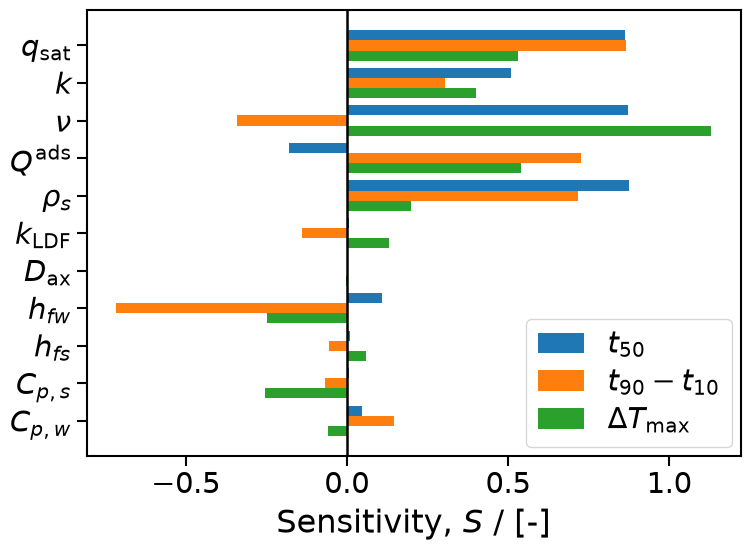

In [4]:
# The isotherm, heat-of-adsorption, and mass-transfer inputs are those of CO2. h_w,inf has |S| < 0.06
# for all three measures (table above) and is left out, so that the labels stay legible at print size.
labels = {
    "saturation_loading_CO2": r"$q_{\mathrm{sat}}$",
    "affinity_CO2": r"$k$",
    "sips_exponent_CO2": r"$\nu$",
    "heat_of_adsorption_CO2": r"$Q^{\mathrm{ads}}$",
    "particle_density": r"$\rho_s$",
    "mass_transfer_coefficient_CO2": r"$k_{\mathrm{LDF}}$",
    "axial_dispersion_coefficient": r"$D_{\mathrm{ax}}$",
    "heat_transfer_gas_wall": r"$h_{fw}$",
    "heat_transfer_gas_solid": r"$h_{fs}$",
    "heat_capacity_solid": r"$C_{p,s}$",
    "heat_capacity_wall": r"$C_{p,w}$",
}
assert (SENSITIVITY.drop(index=list(labels)).abs() < 0.06).all().all()
measures = {
    "t50_s": r"$t_{50}$",
    "spread_s": r"$t_{90} - t_{10}$",
    "dTmax_K": r"$\Delta T_{\max}$",
}
order = list(labels)[::-1]
positions = np.arange(len(order))
height = 0.27

fig, ax = plt.subplots()
for offset, (measure, label) in zip((height, 0.0, -height), measures.items()):
    ax.barh(positions + offset, SENSITIVITY.loc[order, measure], height=height, label=label)
ax.axvline(0.0, color="black", linewidth=1.8)
ax.set_yticks(positions, [labels[name] for name in order])
ax.set_xlabel(r"Sensitivity, $S$ / [-]")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "sensitivity_coefficients.pdf", dpi=300)
plt.show()

## (b) CO$_2$ mass-transfer coefficient

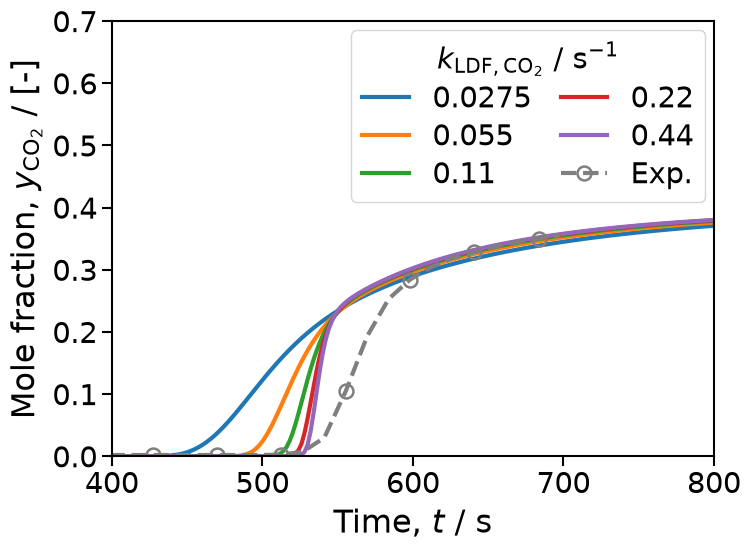

In [5]:
reference = load_reference()
runs = MEASURES[MEASURES["parameter"].isin(["mass_transfer_coefficient_CO2", "reference"])]
runs = runs[~runs["multiplier"].isin(LOCAL_MULTIPLIERS)].sort_values("multiplier")
base = json.loads((ROOT / "simulations" / "reference" / "simulation.json").read_text())
base_coefficient = next(c for c in base["Components"] if c["Name"] == "CO2")["MassTransferCoefficient"]

fig, ax = plt.subplots()
for color, run in zip(("C0", "C1", "C2", "C3", "C4"), runs.itertuples()):
    outlet = load_outlet(run.directory)
    ax.plot(outlet["time"], outlet["CO2"], color=color, linestyle="-", label=f"{base_coefficient * run.multiplier:.3g}")
time, fraction = reference["CO2"]
ax.plot(time, fraction, color="C7", linestyle="--", marker="o", markerfacecolor="none", markevery=3,
        label="Exp.")
ax.set_xlim(400.0, 800.0)
ax.set_ylim(0.0, 0.7)
ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Mole fraction, $y_{\mathrm{CO_2}}$ / [-]")
ax.legend(loc="upper right", ncol=2, title=r"$k_{\mathrm{LDF},\mathrm{CO_2}}$ / s$^{-1}$")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "sensitivity_mass_transfer.pdf", dpi=300)
plt.show()

## (c) Axial dispersion coefficient (benchmark levels)

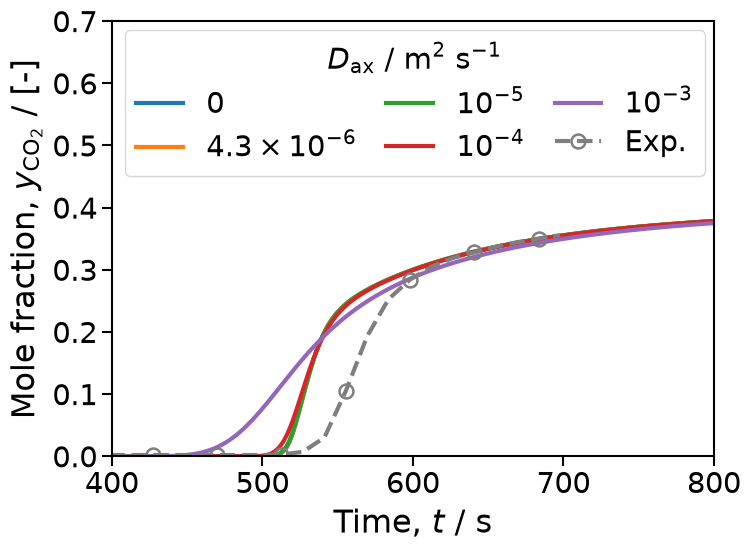

In [6]:
reference = load_reference()
sweep = MEASURES[(MEASURES["parameter"] == "axial_dispersion_coefficient") & (MEASURES["kind"] == "sweep")]
# The reference input has 4.3e-6 m2/s for the adsorbing components (1e-5 m2/s for helium).
runs = [(run.value, run.directory) for run in sweep.itertuples()] + [(4.3e-6, "simulations/reference")]
dispersion_labels = {
    0.0: r"$0$",
    4.3e-6: r"$4.3 \times 10^{-6}$",
    1e-5: r"$10^{-5}$",
    1e-4: r"$10^{-4}$",
    1e-3: r"$10^{-3}$",
}

fig, ax = plt.subplots()
for color, (value, directory) in zip(("C0", "C1", "C2", "C3", "C4"), sorted(runs)):
    outlet = load_outlet(directory)
    ax.plot(outlet["time"], outlet["CO2"], color=color, linestyle="-", label=dispersion_labels[value])
time, fraction = reference["CO2"]
ax.plot(time, fraction, color="C7", linestyle="--", marker="o", markerfacecolor="none", markevery=3,
        label="Exp.")
ax.set_xlim(400.0, 800.0)
ax.set_ylim(0.0, 0.7)
ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Mole fraction, $y_{\mathrm{CO_2}}$ / [-]")
ax.legend(loc="upper right", ncol=3, title=r"$D_{\mathrm{ax}}$ / m$^2$ s$^{-1}$")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "sensitivity_dispersion.pdf", dpi=300)
plt.show()

## (d) Number of grid points (benchmark levels)

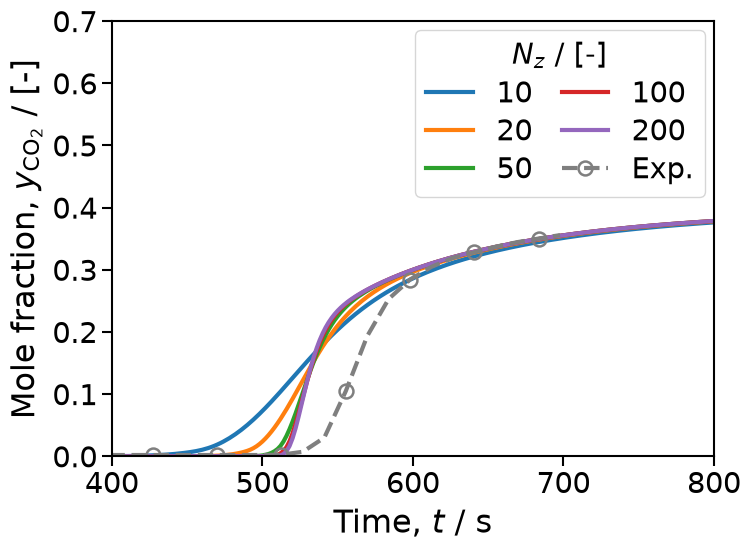

In [7]:
reference = load_reference()
sweep = MEASURES[MEASURES["parameter"] == "grid_points"]
runs = [(int(run.value), run.directory) for run in sweep.itertuples()] + [(100, "simulations/reference")]

fig, ax = plt.subplots()
for color, (grid_points, directory) in zip(("C0", "C1", "C2", "C3", "C4"), sorted(runs)):
    outlet = load_outlet(directory)
    ax.plot(outlet["time"], outlet["CO2"], color=color, linestyle="-", label=f"{grid_points}")
time, fraction = reference["CO2"]
ax.plot(time, fraction, color="C7", linestyle="--", marker="o", markerfacecolor="none", markevery=3,
        label="Exp.")
ax.set_xlim(400.0, 800.0)
ax.set_ylim(0.0, 0.7)
ax.set_xlabel(r"Time, $t$ / s")
ax.set_ylabel(r"Mole fraction, $y_{\mathrm{CO_2}}$ / [-]")
ax.legend(loc="upper right", ncol=2, title=r"$N_z$ / [-]")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "sensitivity_grid.pdf", dpi=300)
plt.show()

## Numbers quoted in the paper

In [8]:
reference_run = MEASURES[MEASURES["kind"] == "reference"].iloc[0]
table = MEASURES[MEASURES["kind"] != "local"][["directory", "t50_s", "spread_s", "dTmax_K"]].copy()
for measure in ("t50_s", "spread_s", "dTmax_K"):
    table[f"{measure} rel."] = table[measure] / reference_run[measure] - 1.0
print(table.round(4).to_string(index=False))

# Numerical dispersion: 200 grid points with the dispersion that the 100-point grid adds numerically.
check = MEASURES[MEASURES["kind"] == "check"].iloc[0]
reference_outlet = load_outlet("simulations/reference")
check_outlet = load_outlet(check["directory"])
deviation = np.abs(
    np.interp(reference_outlet["time"], check_outlet["time"], check_outlet["CO2"]) - reference_outlet["CO2"]
).max() / FEED_MOLE_FRACTION["CO2"]
print(f"Numerical-dispersion check: t50 {check['t50_s']:.1f} s (reference {reference_run['t50_s']:.1f} s), "
      f"spread {check['spread_s']:.1f} s (reference {reference_run['spread_s']:.1f} s), "
      f"max |y - y_ref| / y_in = {deviation:.3f}")

                                          directory    t50_s  spread_s  dTmax_K  t50_s rel.  spread_s rel.  dTmax_K rel.
                              simulations/reference 541.3042  193.8766  23.6512      0.0000         0.0000        0.0000
    simulations/mass_transfer_coefficient_CO2/x0.25 530.7359  278.3128  17.1252     -0.0195         0.4355       -0.2759
    simulations/mass_transfer_coefficient_CO2/x0.50 538.1780  221.3398  20.9220     -0.0058         0.1417       -0.1154
    simulations/mass_transfer_coefficient_CO2/x2.00 542.7745  180.7772  25.2592      0.0027        -0.0676        0.0680
    simulations/mass_transfer_coefficient_CO2/x4.00 543.4842  174.3819  26.1119      0.0040        -0.1006        0.1040
         simulations/axial_dispersion_coefficient/0 541.2796  193.7011  23.6833     -0.0000        -0.0009        0.0014
      simulations/axial_dispersion_coefficient/1e-5 541.3380  194.1101  23.6086      0.0001         0.0012       -0.0018
      simulations/axial_dispersi